<a href="https://colab.research.google.com/github/rithikakknair/OIBSIP/blob/main/Python-lvl2-Task1-house-price-orediction/lvl2_Task1_house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Missing Values Check ---
Area_sqft           0
Rooms               0
Age_years           0
Location_Quality    0
Price               0
dtype: int64


--- Descriptive Statistics ---
         Area_sqft       Rooms   Age_years          Price
count   500.000000  500.000000  500.000000     500.000000
mean   2688.826000    3.034000   24.200000  483819.460031
std    1045.345266    1.455018   14.350745  161635.338973
min     801.000000    1.000000    0.000000  137358.111522
25%    1819.000000    2.000000   11.000000  361011.502145
50%    2658.000000    3.000000   25.000000  479401.702349
75%    3611.750000    4.000000   36.000000  620359.925050
max    4496.000000    5.000000   49.000000  800498.304609




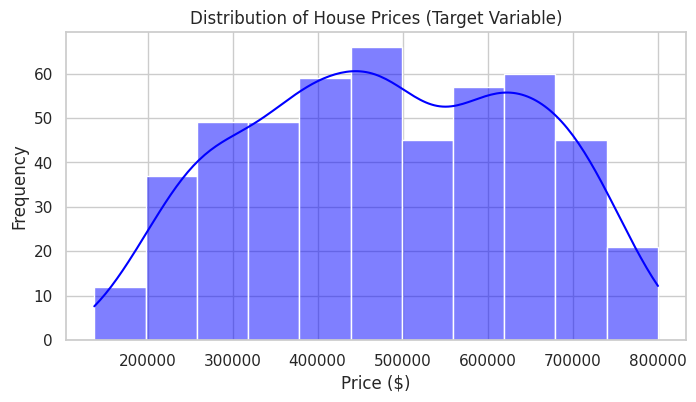

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

# For demonstration, we create a synthetic dataset styled after housing datasets (e.g., Kaggle/Ames housing)[span_4](start_span)[span_4](end_span)[span_5](start_span)[span_5](end_span)
# To use your own downloaded CSV, replace this part with: df = pd.read_csv('your_file_name.csv')
np.random.seed(42)
n_samples = 500

data = {
    'Area_sqft': np.random.randint(800, 4500, size=n_samples),
    'Rooms': np.random.randint(1, 6, size=n_samples),
    'Age_years': np.random.randint(0, 50, size=n_samples),
    'Location_Quality': np.random.choice(['Low', 'Medium', 'High'], size=n_samples),
}

price = (
    50000
    + data['Area_sqft'] * 150
    + data['Rooms'] * 10000
    - data['Age_years'] * 1200
    + pd.Series(data['Location_Quality']).map({'Low': 0, 'Medium': 25000, 'High': 60000})
    + np.random.normal(0, 15000, size=n_samples)
)

df = pd.DataFrame(data)
df['Price'] = price

# 1. Null Check
print("--- Missing Values Check ---")
print(df.isnull().sum())
print("\n")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print(df.describe())
print("\n")

# 3. Distribution of Target Variable (Price)
plt.figure(figsize=(8, 4))
sns.histplot(df['Price'], kde=True, color='blue')
plt.title('Distribution of House Prices (Target Variable)')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')
plt.show()

Feature Selection Discussion :
Area_sqft: Selected as a primary predictor because larger living spaces strongly scale with property market value.
  
Rooms: Selected because a higher room count increases general property utility and demand.
  
Age_years: Selected because older properties typically involve higher maintenance costs, serving as a negative predictor.
  
Location_Quality: Selected to capture baseline locality differences (e.g., neighborhood quality, proximity to centers) which significantly alter real estate prices.

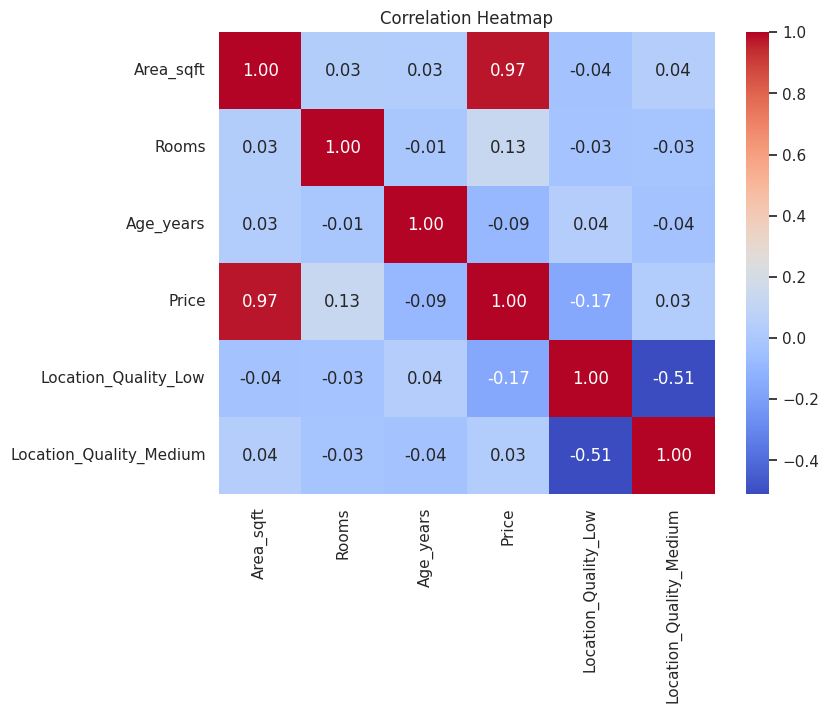

In [ ]:
# Handle missing values (if any exist, fill numeric columns with median, etc.)
# Since our synthetic dataset has no nulls, this ensures safety for real datasets:
df.fillna(df.median(numeric_only=True), inplace=True)

# Encode categorical features (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=['Location_Quality'], drop_first=True)

# Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Train / Test Split (80/20)
X = df_encoded.drop(columns=['Price'])
y = df_encoded['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 2. Train the Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Evaluate the Model
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation ---")
print(f"Mean Squared Error (MSE) : {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:,.2f}")
print(f"R² Score : {r2:.4f}")

--- Model Evaluation ---
Mean Squared Error (MSE) : 248,755,477.30
Root Mean Squared Error (RMSE) : 15,771.98
R² Score : 0.9907


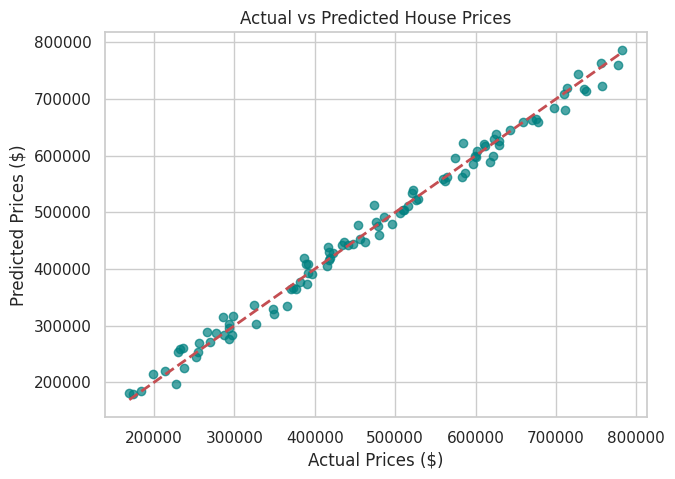

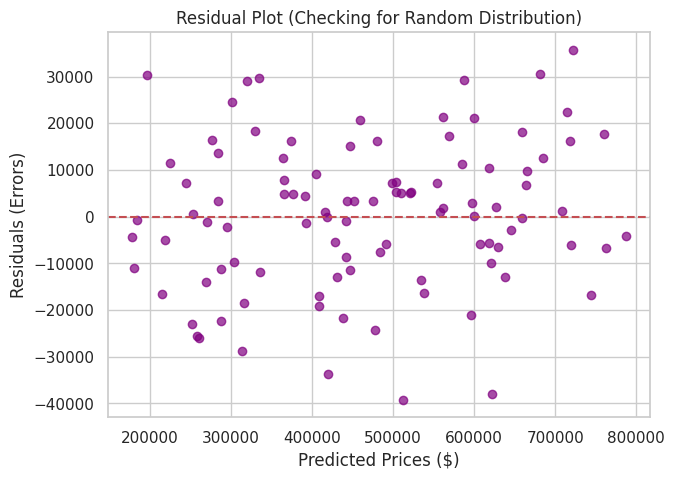

In [ ]:
# 1. Scatter Plot: Actual vs. Predicted Prices
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Prices ($)')
plt.ylabel('Predicted Prices ($)')
plt.title('Actual vs Predicted House Prices')
plt.show()

# 2. Residual Plot
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.7, color='purple')
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Prices ($)')
plt.ylabel('Residuals (Errors)')
plt.title('Residual Plot (Checking for Random Distribution)')
plt.show()

In [ ]:
from sklearn.linear_model import Ridge

# 1. Coefficient Analysis
coeff_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("--- Feature Coefficients ---")
print(coeff_df)
print("\n")

# 2. (Bonus) Ridge Regularized Model Comparison
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print("--- Bonus: Ridge Regression Comparison ---")
print(f"Ridge RMSE : {ridge_rmse:,.2f}")
print(f"Ridge R² Score : {ridge_r2:.4f}")

--- Feature Coefficients ---
                   Feature   Coefficient
1                    Rooms   9975.921027
0                Area_sqft    149.542301
2                Age_years  -1205.928989
4  Location_Quality_Medium -35813.101146
3     Location_Quality_Low -60824.512320


--- Bonus: Ridge Regression Comparison ---
Ridge RMSE : 15,768.38
Ridge R² Score : 0.9907
